# TD6 - Traitement statistique, géostatistiques et approche systèmes - ENSG 2A (S7)

## Objectifs

Ce notebook reproduit en Python les analyses géostatistiques du TD6 réalisées dans le logiciel **SKUA-Gocad**, en utilisant les bibliothèques Python suivantes :

- **pandas** >> chargement et exploration des données CSV
- **matplotlib** >> visualisation des données
- **numpy** >> calculs statistiques
- **gstlearn** >> analyses géostatistiques (variogramme, krigeage)
- **ipywidgets** >> réglage manuel interactif des variogrammes

## Données

Les données utilisées sont le jeu de données **Jura** :

- **259 échantillons** de sol en 2D
- **Coordonnées** X et Y en **kilomètres**
- **Variables** : Cd,Co,Cr,Cu,Ni,Zn,Pb
- **Variable étudiée** : Pb (Plomb) en mg/kg

## 1. Chargement des données

Les données de **Jura** sont chargées avec la bibliothèque **pandas** depuis un fichier CSV contenant les coordonnées **X**, **Y** et les propriétés géochimiques **(Cd, Co, Cr, Cu, Ni, Zn, Pb)**.
La variable étudiée est le **Plomb (Pb)** en mg/kg.

In [ ]:
# ---- Chargement des données ----
import sys
import os

# Ajout du chemin d'importation pour le module geostat_utils (remonte de jura/ jusqu'à src/)
sys.path.append(os.path.abspath(os.path.join("..", "..")))
import geostat_utils as gutils

# Chargement des données avec le module utilitaire
data_jura = gutils.charger_donnees_jura()

# ---- Afficher les premières lignes ----
print("Trois premières lignes")
display(data_jura.head(3))

# ---- Afficher les dernières lignes ----
print("Deux dernières lignes")
display(data_jura.tail(2))

data_jura.info()


## 2. Visualisation spatiale

Les points d'échantillonnage du **Plomb (Pb)** sont représentés selon leurs coordonnées **X** et **Y**, colorés selon la concentration, ce qui permet d'observer la distribution spatiale et d'identifier les zones d'enrichissement.

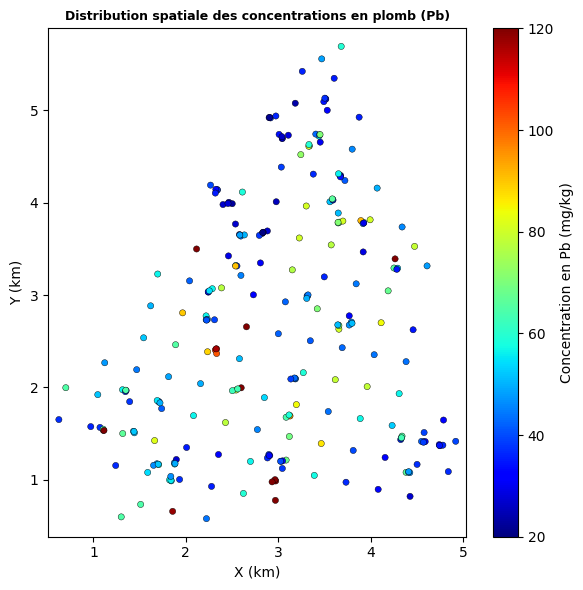

In [2]:
import matplotlib.pyplot as plt
#----carte spatiale du plomb (Pb)----
plt.figure(figsize=(6, 6))
plt.scatter(data_jura['X'], data_jura['Y'], c=data_jura['Pb'], cmap='jet', s=20, edgecolor='k', linewidth=0.3, vmin=20, vmax=120)
plt.colorbar(label='Concentration en Pb (mg/kg)')
plt.xlabel("X (km)")
plt.ylabel("Y (km)")
plt.title("Distribution spatiale des concentrations en plomb (Pb)", fontsize=9, fontweight='bold', loc='center')
plt.axis("equal") 
plt.tight_layout()  
plt.show()

## 3. Histogramme et courbe cumulative

L'histogramme permet d'observer la distribution des concentrations en **Plomb (Pb)**, d'identifier la présence de valeurs extrêmes et d'évaluer la dispersion des concentrations. Un histogramme est construit avec **50 classes (bins)** accompagné d'une courbe cumulative.

Les statistiques descriptives (moyenne, médiane, quartiles, IQR, écart-type, variance) sont calculées directement avec **numpy** et affichées sur la courbe cumulative.

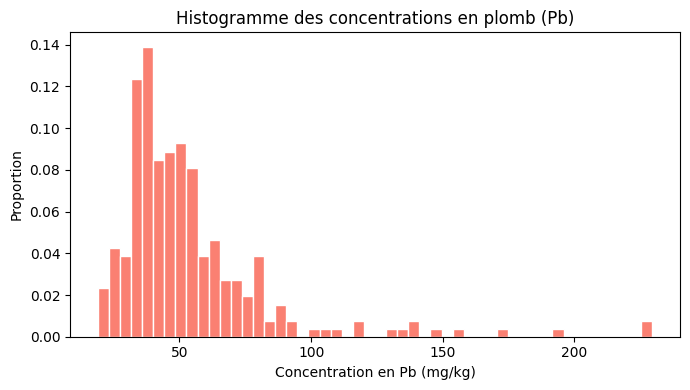

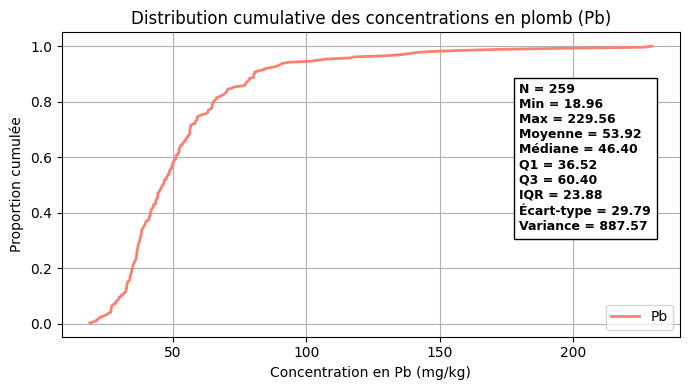

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# ----calcul histogramme du plomb (Pb)----

Pb = data_jura['Pb']

plt.figure(figsize=(7, 4))

plt.hist(Pb, bins=50, weights=np.ones(len(Pb)) / len(Pb), color='salmon', edgecolor='white')
plt.title("Histogramme des concentrations en plomb (Pb)")
plt.xlabel("Concentration en Pb (mg/kg)")
plt.ylabel("Proportion")
plt.tight_layout()
plt.show()
# ----calcul statistiques du plomb (Pb)----

nombre_mesures = len(Pb)
min_value = np.min(Pb)
max_value = np.max(Pb)
moyenne_pb = np.mean(Pb)
mediane_pb = np.median(Pb)
premier_quartile = np.percentile(Pb, 25)
troisieme_quartile = np.percentile(Pb, 75)   
IQR = troisieme_quartile - premier_quartile           
ecart_type_pb = np.std(Pb, ddof=1)
variance_pb = np.var(Pb, ddof=1)
Pb_trie = np.sort(Pb)
Pb_cumulative = np.arange(1, len(Pb_trie)+1) / len(Pb_trie)

#----Distribution cumulative du plomb (Pb)----

plt.figure(figsize=(7, 4))

plt.plot(Pb_trie, Pb_cumulative, color='salmon', linewidth=2, label='Pb')
plt.title("Distribution cumulative des concentrations en plomb (Pb)")
plt.xlabel("Concentration en Pb (mg/kg)")
plt.ylabel("Proportion cumulée")
plt.legend(loc='lower right')

#----Affichage Texte statistiques sur le graphe----

text_stats = (
    f"N = {nombre_mesures}\n"
    f"Min = {min_value:.2f}\n"
    f"Max = {max_value:.2f}\n"
    f"Moyenne = {moyenne_pb:.2f}\n"
    f"Médiane = {mediane_pb:.2f}\n"
    f"Q1 = {premier_quartile:.2f}\n"
    f"Q3 = {troisieme_quartile:.2f}\n"
    f"IQR = {IQR:.2f}\n"
    f"Écart-type = {ecart_type_pb:.2f}\n"
    f"Variance = {variance_pb:.2f}"
)
plt.text(0.74, 0.35,                     
    text_stats,
    transform=plt.gca().transAxes,
    fontsize=9,
    fontweight='bold',
    bbox=dict(facecolor='white', edgecolor='black')
)
plt.grid()
plt.tight_layout()
plt.show()

**D'après la courbe cumulative :**

- **60%** des échantillons ont une concentration en Pb inférieure à **50 mg/kg**
- **95%** des échantillons ont une concentration en Pb inférieure à **100 mg/kg**
- Quelques valeurs extrêmes dépassent **200 mg/kg**